# Predicting late MapleFreight deliveries (Slack to dispatch)

AML 3303 · Assessment 1  
Student ID: c0968446

## Setting

MapleFreight moves around 8,000 loads a week through Ontario, Quebec and the Prairies. Late deliveries trigger service credits. On-time performance fell from 94% to 88%, and the team often learns about a miss only after the customer calls.

## Task

I need an early late-risk score for shipments that are still moving, plus a Slack ping to `#dispatch-alerts` so dispatch can re-route or warn the account before the window closes.

## What success looks like

- Point out the main delay drivers in this export
- Train a classifier for `delivered_late`
- Alert on high-risk IDs through Slack
- Leave a short ops recommendation list

## Setup

In [1]:
from pathlib import Path
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
import requests

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    roc_auc_score,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd()
if not (ROOT / "data" / "maplefreight_delivery_delay_dataset.csv").exists():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "data" / "maplefreight_delivery_delay_dataset.csv").exists():
            ROOT = p
            break

DATA = ROOT / "data" / "maplefreight_delivery_delay_dataset.csv"
load_dotenv(ROOT / ".env")

RS = 33
HOLD = 0.22

print("root:", ROOT)
print("csv:", DATA.exists())
print("webhook loaded:", bool(os.getenv("SLACK_WEBHOOK_URL")))

root: c:\Users\prati\Downloads\Assignment1-Pratik-c0968446-compres\Assignment1-Pratik-c0968446
csv: True
webhook loaded: True


## Data check

6,035 shipments, 23 columns, target `delivered_late` (~21% late). A model that always says "on time" would look ~79% accurate and still miss every late load.

`actual_transit_hours` is only known after delivery, so it is excluded.

In [2]:
raw = pd.read_csv(DATA)
print(raw.shape)
print("late rate", round(raw["delivered_late"].mean(), 4))
raw.head(4)

(6035, 23)
late rate 0.2058


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,2,0,7.53,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,0,0,1.00,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,0,0,7.12,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,0,0,7.61,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0


In [3]:
print(raw.isna().sum()[raw.isna().sum() > 0])
print("duplicates", raw.duplicated().sum())
print(raw["service_level"].value_counts())
print(raw["goods_type"].value_counts())

driver_experience_years    210
weather_condition          150
traffic_index              121
fuel_cost_cad              240
dtype: int64
duplicates 32
service_level
Standard    3219
Express     1442
Economy     1254
standard      74
express       27
economy       19
Name: count, dtype: int64
goods_type
General Freight    2974
Refrigerated        924
Fragile             895
Bulk                744
Hazardous           498
Name: count, dtype: int64


Missing values hit driver experience, weather, traffic index and fuel cost. There are duplicate rows, and `service_level` has mixed casing that I fix in cleaning.

## EDA

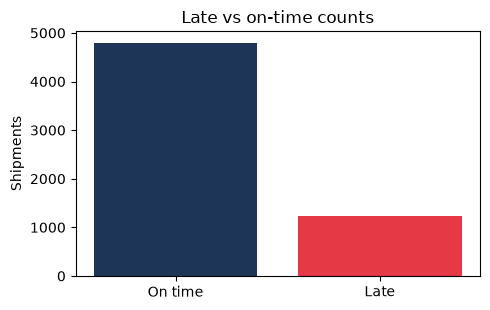

In [4]:
fig, ax = plt.subplots(figsize=(5, 3.2))
c = raw["delivered_late"].value_counts().sort_index()
ax.bar(["On time", "Late"], c.values, color=["#1D3557", "#E63946"])
ax.set_title("Late vs on-time counts")
ax.set_ylabel("Shipments")
plt.tight_layout()
plt.show()

In [5]:
t = raw.copy()
t["service_level"] = t["service_level"].astype(str).str.strip().str.title()
print("carrier late %")
print((t.groupby("carrier")["delivered_late"].mean() * 100).round(1).sort_values(ascending=False))
print("\npriority late %")
print((t.groupby("customer_priority_tier")["delivered_late"].mean() * 100).round(1).sort_values(ascending=False))
print("\nweather late %")
print((t.groupby("weather_condition")["delivered_late"].mean() * 100).round(1).sort_values(ascending=False))

carrier late %
carrier
Contract Owner-Op     35.9
PrairieLine           26.5
QuebecExpress         22.4
NorthStar Carriers    22.0
MapleFreight Fleet    12.9
Name: delivered_late, dtype: float64

priority late %
customer_priority_tier
Gold      20.8
Bronze    20.7
Silver    20.4
Name: delivered_late, dtype: float64

weather late %
weather_condition
Storm    46.3
Snow     33.5
Fog      21.3
Rain     20.9
Clear    14.0
Name: delivered_late, dtype: float64


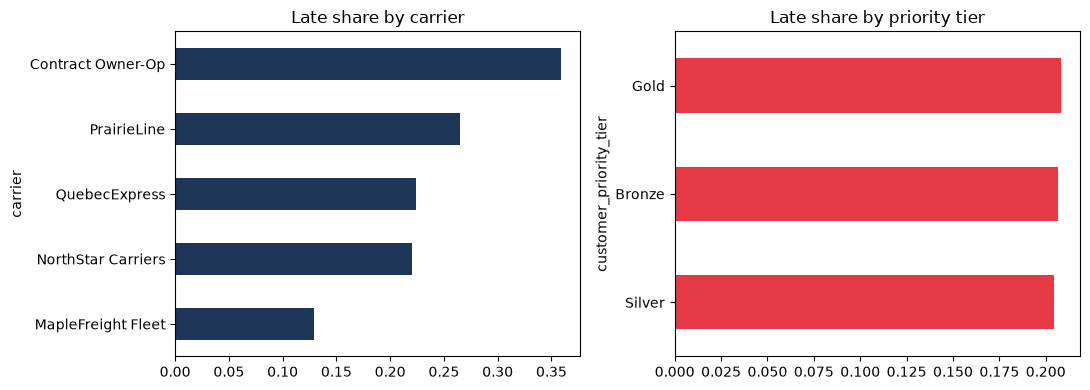

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
(t.groupby("carrier")["delivered_late"].mean().sort_values()
   .plot(kind="barh", ax=axes[0], color="#1D3557"))
axes[0].set_title("Late share by carrier")
(t.groupby("customer_priority_tier")["delivered_late"].mean().sort_values()
   .plot(kind="barh", ax=axes[1], color="#E63946"))
axes[1].set_title("Late share by priority tier")
plt.tight_layout()
plt.show()

In [7]:
nums = [
    "pickup_delay_minutes", "distance_km", "weight_kg", "traffic_index",
    "num_stops", "scheduled_transit_hours", "prior_late_deliveries_30d",
    "route_congestion_score", "fuel_cost_cad", "driver_experience_years",
]
cmp = t.groupby("delivered_late")[nums].mean().T
cmp.columns = ["on_time", "late"]
cmp["ratio"] = cmp["late"] / cmp["on_time"]
cmp.sort_values("ratio", ascending=False).round(3)

,on_time,late,ratio
pickup_delay_minutes,18.385,28.021,1.524
num_stops,2.343,2.995,1.278
weight_kg,6590.926,8230.021,1.249
scheduled_transit_hours,9.996,12.447,1.245
prior_late_deliveries_30d,1.243,1.546,1.243
distance_km,602.269,747.670,1.241
traffic_index,53.656,60.881,1.135
route_congestion_score,0.440,0.488,1.110
fuel_cost_cad,180.452,181.636,1.007
driver_experience_years,6.714,5.658,0.843


Owner-ops are late more often than the internal fleet. Storm weather stands out. Gold accounts are not automatically safer in this export. On averages, late loads leave pickup later and travel farther with more congestion.

## Cleaning and feature work

In [8]:
def tidy(df: pd.DataFrame) -> pd.DataFrame:
    out = df.drop_duplicates().copy()
    out["service_level"] = out["service_level"].astype(str).str.strip().str.title()
    for col in ["carrier", "goods_type", "customer_priority_tier", "weather_condition"]:
        out[col] = out[col].astype(str).str.strip()
        out.loc[out[col].isin(["nan", "None", "<NA>", "NaN"]), col] = np.nan
    return out.drop(columns=["actual_transit_hours"]).reset_index(drop=True)

def feats(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["fuel_per_km"] = out["fuel_cost_cad"] / out["distance_km"].replace(0, np.nan)
    out["is_express"] = (out["service_level"] == "Express").astype(int)
    out["long_haul"] = (out["distance_km"] >= out["distance_km"].median()).astype(int)
    out["busy_route"] = (
        (out["traffic_index"] >= 60) | (out["route_congestion_score"] >= 0.55)
    ).astype(int)
    out["origin_prov"] = out["origin_city"].astype(str).str.extract(r"([A-Z]{2})$")
    out["dest_prov"] = out["destination_city"].astype(str).str.extract(r"([A-Z]{2})$")
    return out

df = feats(tidy(raw))
print("rows", len(df))
print("late long_haul", round(df.loc[df.long_haul == 1, "delivered_late"].mean(), 3))
print("late short_haul", round(df.loc[df.long_haul == 0, "delivered_late"].mean(), 3))
print("late busy_route", round(df.loc[df.busy_route == 1, "delivered_late"].mean(), 3))
print("late express", round(df.loc[df.is_express == 1, "delivered_late"].mean(), 3))

rows 6003
late long_haul 0.262
late short_haul 0.149
late busy_route 0.255
late express 0.151


Long-haul and busy-route flags track higher late rates. Express is a bit safer than the rest, which matches the service-level EDA. `fuel_per_km` is a rough cost intensity signal.

## Train/test

In [9]:
y = df["delivered_late"]
X = df.drop(columns=["delivered_late", "shipment_id", "origin_city", "destination_city"]).copy()
cats = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
for c in cats:
    X[c] = X[c].astype(object).where(pd.notna(X[c]), np.nan)
nums = [c for c in X.columns if c not in cats]

Xtr, Xte, ytr, yte = train_test_split(
    X, y, test_size=HOLD, random_state=RS, stratify=y
)
print(Xtr.shape, Xte.shape, round(ytr.mean(), 3), round(yte.mean(), 3))

prep = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
    ]), nums),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("oh", OneHotEncoder(handle_unknown="ignore")),
    ]), cats),
])

(4682, 24) (1321, 24) 0.206 0.206


## Models

Baseline first (always on time). Then balanced logistic regression, random forest, and AdaBoost on shallow trees. I care about late-class precision, recall, F1 and the confusion matrix.

==== baseline ====
              precision    recall  f1-score   support

           0      0.794     1.000     0.885      1049
           1      0.000     0.000     0.000       272

    accuracy                          0.794      1321
   macro avg      0.397     0.500     0.443      1321
weighted avg      0.631     0.794     0.703      1321

ROC-AUC 0.5


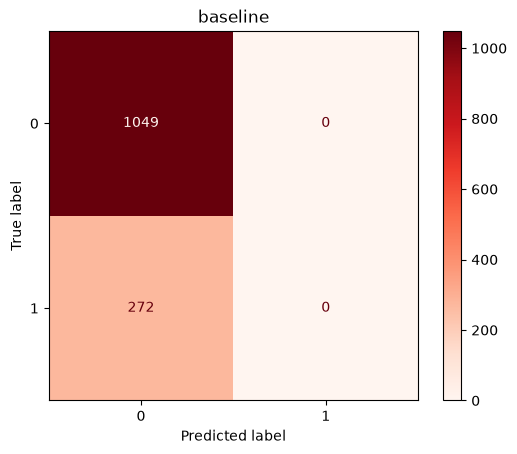

In [10]:
def report(model, Xt, yt, name):
    pred = model.predict(Xt)
    proba = model.predict_proba(Xt)[:, 1] if hasattr(model, "predict_proba") else None
    p, r, f1, _ = precision_recall_fscore_support(yt, pred, average="binary", zero_division=0)
    print("====", name, "====")
    print(classification_report(yt, pred, digits=3, zero_division=0))
    if proba is not None:
        print("ROC-AUC", round(roc_auc_score(yt, proba), 3))
    ConfusionMatrixDisplay(confusion_matrix(yt, pred)).plot(cmap="Reds")
    plt.title(name)
    plt.show()
    return {"model": name, "precision": p, "recall": r, "f1": f1}

base = Pipeline([("prep", prep), ("clf", DummyClassifier(strategy="most_frequent"))])
base.fit(Xtr, ytr)
m0 = report(base, Xte, yte, "baseline")

==== logreg ====
              precision    recall  f1-score   support

           0      0.914     0.731     0.812      1049
           1      0.415     0.735     0.531       272

    accuracy                          0.732      1321
   macro avg      0.665     0.733     0.672      1321
weighted avg      0.811     0.732     0.754      1321

ROC-AUC 0.815


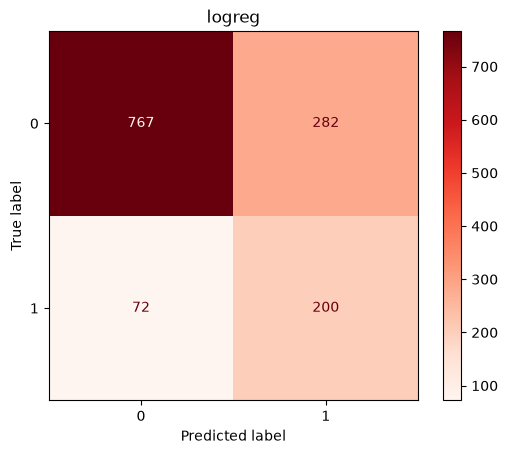

In [11]:
lr = Pipeline([
    ("prep", prep),
    ("clf", LogisticRegression(
        C=1.2, max_iter=3000, class_weight="balanced", random_state=RS
    )),
])
lr.fit(Xtr, ytr)
m1 = report(lr, Xte, yte, "logreg")

==== random_forest ====
              precision    recall  f1-score   support

           0      0.853     0.906     0.878      1049
           1      0.522     0.397     0.451       272

    accuracy                          0.801      1321
   macro avg      0.687     0.651     0.665      1321
weighted avg      0.785     0.801     0.790      1321

ROC-AUC 0.781


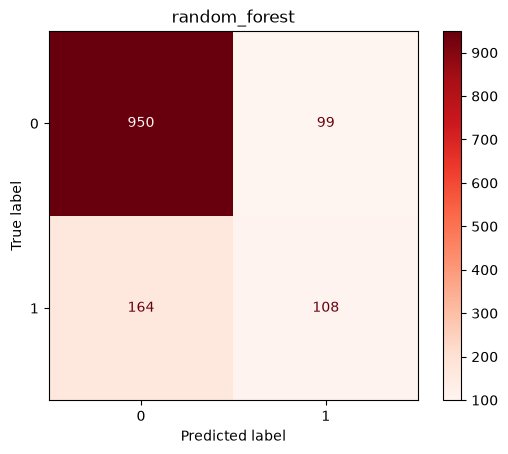

In [12]:
rf = Pipeline([
    ("prep", prep),
    ("clf", RandomForestClassifier(
        n_estimators=220, max_depth=12, min_samples_leaf=4,
        class_weight="balanced_subsample", random_state=RS, n_jobs=-1,
    )),
])
rf.fit(Xtr, ytr)
m2 = report(rf, Xte, yte, "random_forest")

==== adaboost ====
              precision    recall  f1-score   support

           0      0.852     0.708     0.774      1049
           1      0.318     0.526     0.397       272

    accuracy                          0.671      1321
   macro avg      0.585     0.617     0.585      1321
weighted avg      0.742     0.671     0.696      1321

ROC-AUC 0.678


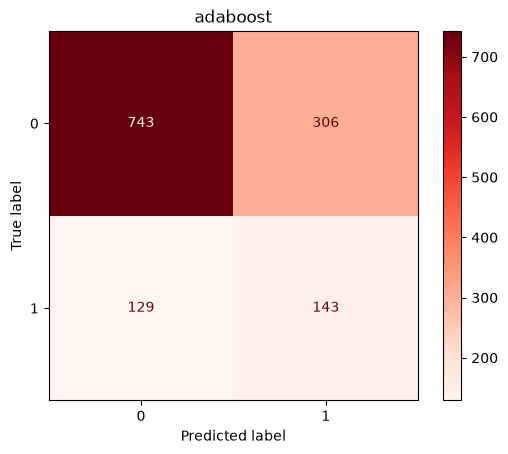

In [13]:
ada = Pipeline([
    ("prep", prep),
    ("clf", AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=RS),
        n_estimators=120,
        learning_rate=0.6,
        random_state=RS,
    )),
])
ada.fit(Xtr, ytr)
m3 = report(ada, Xte, yte, "adaboost")

In [14]:
table = pd.DataFrame([m0, m1, m2, m3]).sort_values(["f1", "recall"], ascending=False)
print(table.to_string(index=False))
pool = {"logreg": lr, "random_forest": rf, "adaboost": ada}
pick = table.iloc[0]["model"]
if pick == "baseline":
    pick = table.iloc[1]["model"]
final_model = pool[pick]
print("final model:", pick)

        model  precision   recall       f1
       logreg   0.414938 0.735294 0.530504
random_forest   0.521739 0.397059 0.450939
     adaboost   0.318486 0.525735 0.396671
     baseline   0.000000 0.000000 0.000000
final model: logreg


The majority baseline is the accuracy trap from the brief. I keep the best non-baseline late-class F1 (recall as tie-breaker). The table above shows the winner for this seed.

## Alert threshold

I scan cuts from 0.28 to 0.72. Rule: late recall at least 0.70, then best F1. If nothing clears 0.70 recall, take max F1.

In [15]:
proba = final_model.predict_proba(Xte)[:, 1]
rows = []
for thr in np.round(np.arange(0.28, 0.73, 0.04), 2):
    pred = (proba >= thr).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(yte, pred, average="binary", zero_division=0)
    rows.append({
        "threshold": thr,
        "precision": round(p, 3),
        "recall": round(r, 3),
        "f1": round(f1, 3),
        "alerts": int(pred.sum()),
    })
thr_df = pd.DataFrame(rows)
thr_df

,threshold,precision,recall,f1,alerts
0,0.28,0.305,0.926,0.459,827
1,0.32,0.328,0.912,0.482,756
2,0.36,0.348,0.886,0.499,693
3,0.40,0.371,0.849,0.517,622
4,0.44,0.396,0.820,0.534,563
5,0.48,0.410,0.765,0.534,507
6,0.52,0.432,0.713,0.538,449
7,0.56,0.454,0.676,0.544,405
8,0.60,0.468,0.614,0.531,357
9,0.64,0.492,0.559,0.523,309


CUT 0.52
              precision    recall  f1-score   support

           0      0.911     0.757     0.827      1049
           1      0.432     0.713     0.538       272

    accuracy                          0.748      1321
   macro avg      0.671     0.735     0.682      1321
weighted avg      0.812     0.748     0.767      1321



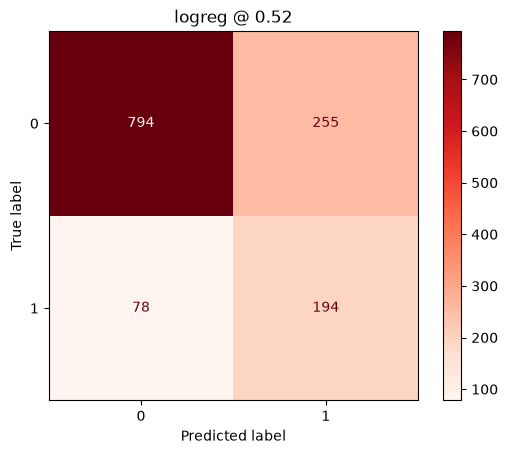

In [16]:
band = thr_df[thr_df["recall"] >= 0.70]
best = band.sort_values(["f1", "precision"], ascending=False).iloc[0] if len(band) else thr_df.sort_values("f1", ascending=False).iloc[0]
CUT = float(best["threshold"])
print("CUT", CUT)

yp = (proba >= CUT).astype(int)
print(classification_report(yte, yp, digits=3, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(yte, yp)).plot(cmap="Reds")
plt.title(f"{pick} @ {CUT}")
plt.show()

Chosen cut: 0.52.

Among thresholds with late recall at least 0.70, 0.52 had the best F1 here (about 0.43 precision, 0.71 recall, 0.54 F1). It sits between a noisy low cut and a stricter 0.55+ cut that would drop more true late loads.


## Explainability

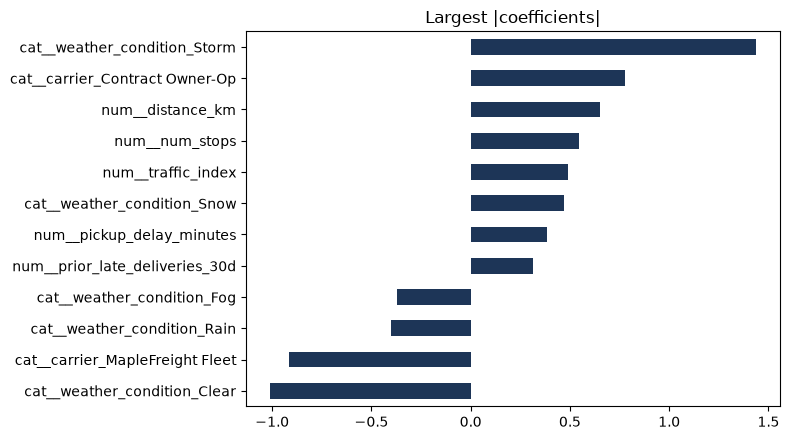

cat__weather_condition_Storm       1.436
cat__weather_condition_Clear      -1.010
cat__carrier_MapleFreight Fleet   -0.915
cat__carrier_Contract Owner-Op     0.780
num__distance_km                   0.651
num__num_stops                     0.546
num__traffic_index                 0.493
cat__weather_condition_Snow        0.468
cat__weather_condition_Rain       -0.401
num__pickup_delay_minutes          0.383
cat__weather_condition_Fog        -0.372
num__prior_late_deliveries_30d     0.314


In [17]:
clf = final_model.named_steps["clf"]
pre = final_model.named_steps["prep"]
names = pre.get_feature_names_out()
if hasattr(clf, "coef_"):
    s = pd.Series(clf.coef_[0], index=names)
    top = s.reindex(s.abs().sort_values(ascending=False).head(12).index)
    title = "Largest |coefficients|"
elif hasattr(clf, "feature_importances_"):
    top = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False).head(12)
    title = "Importances"
else:
    top = pd.Series(dtype=float)
    title = "n/a"

if len(top):
    top.sort_values().plot(kind="barh", color="#1D3557", figsize=(8, 4.5))
    plt.title(title)
    plt.tight_layout()
    plt.show()
    print(top.round(3).to_string())

Weather, carrier, distance/traffic and pickup delay keep rising to the top. That lines up with the EDA story around storm days, owner-ops and late departures.

## Slack notify

Test-set rows stand in for in-transit freight. The message starts with how many loads cleared the cut, then ID, destination, carrier and risk for the top five. Webhook stays in `.env`.

In [18]:
def build_text(frame: pd.DataFrame, cut: float, k: int = 5) -> str:
    n = len(frame)
    lines = [f"ALERT #dispatch | {n} shipments flagged (p>={cut:.2f})", ""]
    for _, row in frame.nlargest(min(k, n), "risk").iterrows():
        lines.append(
            f"{row['shipment_id']} :: {row['destination_city']} :: {row['carrier']} :: {row['risk']:.2f}"
        )
    if n > k:
        lines.append(f"[and {n - k} more]")
    return "\n".join(lines)

def send(text: str) -> bool:
    url = os.getenv("SLACK_WEBHOOK_URL")
    if not url:
        print("no webhook in .env")
        return False
    try:
        r = requests.post(url, json={"text": text}, timeout=15)
    except requests.RequestException as e:
        print(type(e).__name__)
        return False
    print("http", r.status_code)
    return r.status_code == 200

In [19]:
pack = Xte.copy()
pack["risk"] = proba
pack["shipment_id"] = df.loc[Xte.index, "shipment_id"].values
pack["destination_city"] = df.loc[Xte.index, "destination_city"].values
pack["carrier"] = df.loc[Xte.index, "carrier"].values
hot = pack[pack["risk"] >= CUT].copy()
msg = build_text(hot, CUT)
print(msg)
print("sent?", send(msg))

meta = {
    "threshold": CUT,
    "n_risk": int(len(hot)),
    "model": pick,
    "board": table.to_dict("records"),
    "top": hot.nlargest(5, "risk")[["shipment_id", "destination_city", "carrier", "risk"]].to_dict("records"),
    "metrics": {
        "precision": float(precision_recall_fscore_support(yte, yp, average="binary", zero_division=0)[0]),
        "recall": float(precision_recall_fscore_support(yte, yp, average="binary", zero_division=0)[1]),
        "f1": float(precision_recall_fscore_support(yte, yp, average="binary", zero_division=0)[2]),
    },
}
(ROOT / "_run_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
(ROOT / "_last_slack_msg.txt").write_text(msg, encoding="utf-8")

ALERT #dispatch | 449 shipments flagged (p>=0.52)

SHP-105671 :: Calgary AB :: PrairieLine :: 0.99
SHP-104420 :: Toronto ON :: Contract Owner-Op :: 0.98
SHP-101613 :: Quebec City QC :: Contract Owner-Op :: 0.97
SHP-101369 :: Montreal QC :: PrairieLine :: 0.97
SHP-101175 :: Quebec City QC :: PrairieLine :: 0.97
[and 444 more]
http 200
sent? True


326

Save a real Slack capture to `screenshots/slack_alert.png` before turning the repo in.

## Recommendations

1. Hold Economy freight on storm days when the haul is long.  
2. Limit owner-op volume on premium windows until recent late counts drop.  
3. Re-check promised ETA when pickup is already drifting late.  
4. Prefer fleet capacity on busy long-haul lanes.  
5. Pilot Slack at the chosen cut, then raise it if the queue is too noisy.

## Close

The majority baseline looks accurate and finds zero late loads. The selected model plus the tuned threshold is what I would trial with dispatch. Weather, carrier mix, long/busy routes and late pickups keep showing up. Slack keeps the alert short enough to read on a phone.